In [1]:
from pathlib import Path
import json
import yaml
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Load dataset configurations from shared benchmarks/experiments_config.yaml
project_root = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE")
config_path = project_root / "benchmarks" / "experiments_config.yaml"
with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

print(f"Loaded {len(config['queries'])} query configurations")

Loaded 16 dataset configurations


In [ ]:
# Count queries in each dataset
dataset_counts = []

for q in config['queries']:
    query_path = project_root / q['path']

    if query_path.exists():
        try:
            with open(query_path, 'r') as f:
                queries = json.load(f)
                count = len(queries)
                count = min(count, int(q.get('max_train_queries', 20000)))

                dataset_counts.append({
                    'name': q['id'],
                    'dataset': q['dataset_name'],
                    'query_type': q['query_type'],
                    'count': count
                })

                print(f"{q['id']:30s} - {count:5d} queries")
        except Exception as e:
            print(f"Error loading {q['id']}: {e}")
    else:
        print(f"File not found: {query_path}")

lubm_path                      - 20000 queries
lubm_star                      - 20000 queries
swdf_path                      - 20000 queries
swdf_star                      - 20000 queries
wikidata_path                  - 20000 queries
wikidata_star                  - 20000 queries
dbpedia100k_path               - 20000 queries
dbpedia100k_star               - 20000 queries
fb237_v4_ind_path              - 20000 queries
fb237_v4_ind_star              - 20000 queries
fb237_v4_path                  - 20000 queries
fb237_v4_star                  - 20000 queries
wn18rr_v4_ind_path             - 20000 queries
wn18rr_v4_ind_star             -  6767 queries
wn18rr_v4_path                 - 20000 queries
wn18rr_v4_star                 -  7249 queries

Total datasets with queries: 16


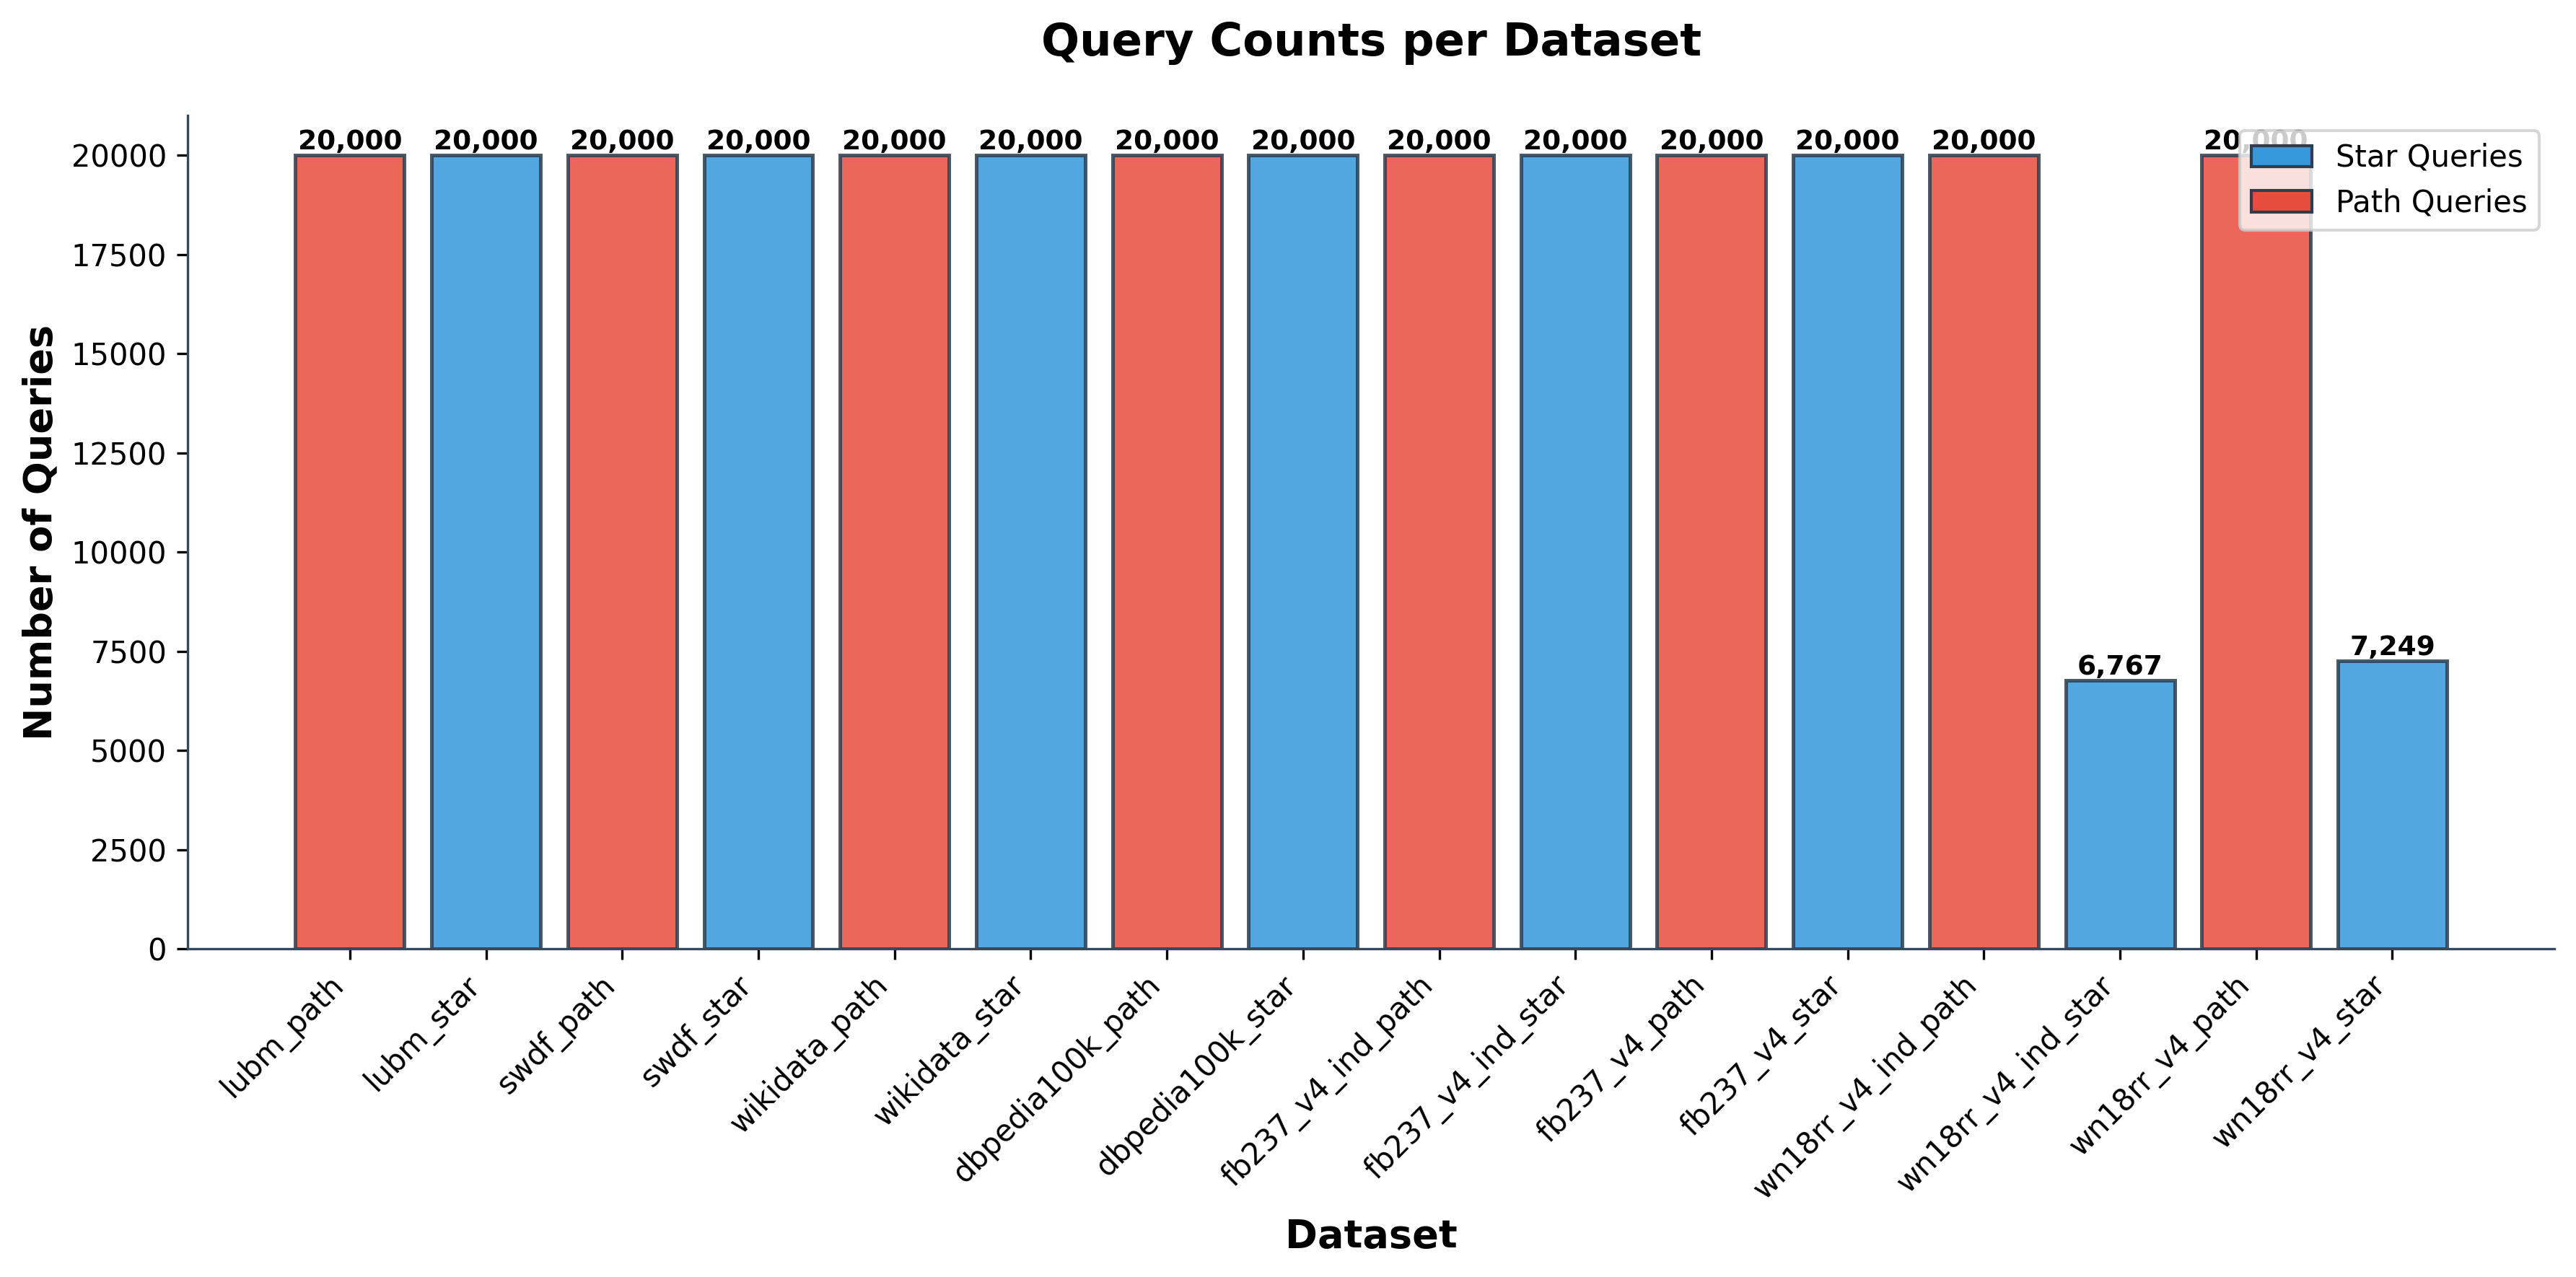


Saved: query_counts.pdf
Total queries across all datasets: 294,016


In [4]:
# Create bar graph
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

names = [d['name'] for d in dataset_counts]
counts = [d['count'] for d in dataset_counts]

# Color bars by query type
colors = []
for d in dataset_counts:
    if d['query_type'] == 'star':
        colors.append('#3498db')  # Blue for star
    elif d['query_type'] == 'path':
        colors.append('#e74c3c')  # Red for path
    else:
        colors.append('#95a5a6')  # Gray for others

bars = ax.bar(range(len(names)), counts, color=colors, edgecolor='#2c3e50', linewidth=1.2, alpha=0.85)

# Add value labels on top of bars
for i, (bar, count) in enumerate(zip(bars, counts)):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

# Styling
ax.set_xlabel('Dataset', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Queries', fontsize=13, fontweight='bold')
ax.set_title('Query Counts per Dataset', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=45, ha='right', fontsize=10)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#34495e')
ax.spines['bottom'].set_color('#34495e')

# Add grid
ax.grid(False)
ax.set_axisbelow(True)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='#2c3e50', label='Star Queries'),
    Patch(facecolor='#e74c3c', edgecolor='#2c3e50', label='Path Queries')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=10)

plt.tight_layout()
plt.savefig('query_counts.pdf', bbox_inches='tight', dpi=300)
plt.show()

print("\nSaved: query_counts.pdf")
print(f"Total queries across all datasets: {sum(counts):,}")

In [5]:
# Print summary statistics
print("Summary Statistics:")
print(f"{'='*60}")
print(f"Total datasets:        {len(dataset_counts)}")
print(f"Total queries:         {sum(counts):,}")
print(f"Average queries/file:  {sum(counts)/len(dataset_counts):,.1f}")
print(f"Min queries:           {min(counts):,} ({names[counts.index(min(counts))]})")
print(f"Max queries:           {max(counts):,} ({names[counts.index(max(counts))]})")

Summary Statistics:
Total datasets:        16
Total queries:         294,016
Average queries/file:  18,376.0
Min queries:           6,767 (wn18rr_v4_ind_star)
Max queries:           20,000 (lubm_path)
